# 03.3 · 因子评估：IC / RankIC / IR / 衰减

> 算出一个因子后，第一个问题就是：**它真的能预测未来收益吗？预测力有多强、多稳定？**
> 本节学会用**信息系数（IC）**体系客观评估因子，这是因子研究员每天都在做的事，也是面试核心。
>
> 我们会看到一个**真实结果**：20 日反转因子在沪深300大盘股上其实是个**弱因子**——这恰恰说明 IC 评估的价值。

## 一、什么是 IC

**信息系数（Information Coefficient, IC）= 每个交易日，因子值与股票未来收益在截面上的相关系数。**

- 每个交易日得到一个 IC 值，随时间形成一条 IC 序列；
- IC 衡量因子"预测得准不准"：
  - IC > 0：因子值越大，未来收益越高（方向正确）；
  - IC 越接近 1，预测力越强；IC ≈ 0 表示没有预测力。

### IC 与 RankIC
- **Pearson IC**：因子值与未来收益的线性相关系数，对极端值敏感；
- **RankIC（Spearman）**：先分别排名，再算相关，**只看顺序、对极端值稳健，A 股最常用**。
- 实战中"IC"通常默认指 RankIC。

## 二、准备数据并计算未来收益

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from factor_lab.preprocess import process_factor
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
close = D.features(codes, ['$close'], freq='day')['$close'].unstack('instrument')

rev20 = -close.pct_change(20)
rev_p = process_factor(rev20)          # 上节的预处理（Rank 标准化）

# 未来 k 日收益：t 收盘 -> t+k 收盘
def fwd_returns(k):
    return close.shift(-k) / close - 1
fwd1 = fwd_returns(1)
print('因子与未来收益面板:', rev_p.shape, fwd1.shape)

[27456:MainThread](2026-10-29 19:41:24,465) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[27456:MainThread](2026-10-29 19:41:25,944) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[27456:MainThread](2026-10-29 19:41:25,945) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

因子与未来收益面板: (2139, 300) (2139, 300)


## 三、逐截面计算 IC / RankIC

对每个交易日，取该截面的因子值和未来收益，计算相关系数：

In [2]:
def ic_series(factor, fwd, method='spearman', min_count=10):
    out = {}
    for dt in factor.index.intersection(fwd.index):
        f, r = factor.loc[dt], fwd.loc[dt]
        v = f.notna() & r.notna()
        if v.sum() > min_count:
            out[dt] = f[v].corr(r[v], method=method)
    return pd.Series(out).sort_index()

rank_ic = ic_series(rev_p, fwd1, method='spearman')   # RankIC
pear_ic = ic_series(rev_p, fwd1, method='pearson')    # Pearson IC
print('RankIC 天数:', len(rank_ic))
print('RankIC 前5个值:'); print(rank_ic.head().round(4))

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


RankIC 天数: 2138
RankIC 前5个值:
2018-01-02   NaN
2018-01-03   NaN
2018-01-04   NaN
2018-01-05   NaN
2018-01-08   NaN
dtype: float64


## 四、IC 四大核心指标

拿到 IC 序列后，用四个指标刻画因子：

| 指标 | 定义 | 含义 |
|---|---|---|
| **IC 均值** | IC 序列的平均值 | 预测力的强弱 |
| **IC 标准差** | IC 序列的波动 | 预测的稳定性 |
| **IR（信息比率）** | IC 均值 / IC 标准差 | 风险调整后的预测力，**最重要** |
| **IC 胜率** | IC > 0 的天数占比 | 预测方向正确的概率 |

**经验判断标准（A 股、RankIC）：**
- IC 均值：|IC| > 0.03 较好，> 0.05 优秀；
- IR：> 0.5 较好，> 1.0 优秀；
- IC 胜率：> 50% 即可，> 55% 较好。

In [3]:
def ic_summary(ic):
    return pd.Series({
        'IC均值': ic.mean(), 'IC标准差': ic.std(),
        'IR': ic.mean()/ic.std(), 'IC胜率': (ic > 0).mean()})

print('=== 20日反转因子（RankIC）===')
print(ic_summary(rank_ic).round(4))
print('\n=== 对比：Pearson IC ===')
print(ic_summary(pear_ic).round(4))

=== 20日反转因子（RankIC）===
IC均值     0.0133
IC标准差    0.2220
IR       0.0601
IC胜率     0.5150
dtype: float64

=== 对比：Pearson IC ===
IC均值    -0.0052
IC标准差    0.2091
IR      -0.0248
IC胜率     0.4794
dtype: float64


**如何解读这个结果？**
- IC 均值约 0.013、IR 约 0.06、胜率约 52%——**全部低于"有效因子"门槛**；
- 说明在沪深300大盘股上，"过去20天跌得多就反弹"的规律**很弱、不稳定**。
- 原因：大盘蓝筹信息效率高、被充分研究，简单的反转效应微弱；反转效应在小盘股、特定情绪期更明显。
- **这不是失败，而是因子研究的常态：大部分"听起来合理"的因子，经 IC 检验后都会被淘汰。**

## 五、IC 时间序列：看稳定性与极端行情

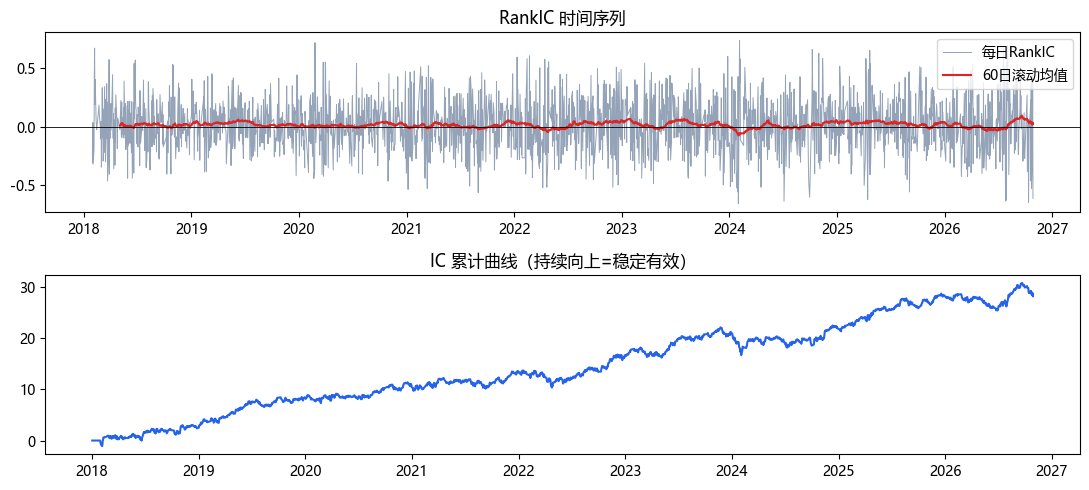

IC 极端值:
  最小 -0.66 @ 2024-02-01
  最大 0.73 @ 2024-02-05

分年度 IC 均值：
2018    0.0108
2019    0.0247
2020    0.0082
2021    0.0120
2022    0.0137
2023    0.0182
2024    0.0032
2025    0.0261
2026    0.0002
dtype: float64


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5))
axes[0].plot(rank_ic.index, rank_ic, color='#94a3b8', lw=.7, label='每日RankIC')
axes[0].plot(rank_ic.index, rank_ic.rolling(60).mean(), color='#dc2626', lw=1.5, label='60日滚动均值')
axes[0].axhline(0, color='black', lw=.6); axes[0].legend(); axes[0].set_title('RankIC 时间序列')
axes[1].plot(rank_ic.index, (rank_ic.fillna(0)).cumsum(), color='#2563eb')
axes[1].set_title('IC 累计曲线（持续向上=稳定有效）')
plt.tight_layout(); plt.show()

print('IC 极端值:')
print('  最小 %.2f @ %s' % (rank_ic.min(), rank_ic.idxmin().date()))
print('  最大 %.2f @ %s' % (rank_ic.max(), rank_ic.idxmax().date()))
print('\n分年度 IC 均值：')
print(rank_ic.groupby(rank_ic.index.year).mean().round(4))

图中可以看到：
- 2024 年初 IC 出现 ±0.7 的极端值——那是**微盘股流动性危机**（2024年1–2月小盘股崩盘、2月5日强力反弹），极端情绪下因子短期"失灵/反转"；
- 分年度 IC 时正时负、多数年份接近 0，进一步说明该因子不稳定。

## 六、IC 衰减：预测力能维持多久

对未来 1、2、3、5、10、20 日收益分别算 IC，看因子的预测力随持有期如何变化（衰减）。

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


       IC均值      IR      胜率
持有期                        
1    0.0133  0.0601  0.5150
2    0.0125  0.0589  0.4946
3    0.0135  0.0645  0.5005
5    0.0142  0.0684  0.4986
10   0.0132  0.0665  0.5021
20   0.0200  0.1024  0.4823


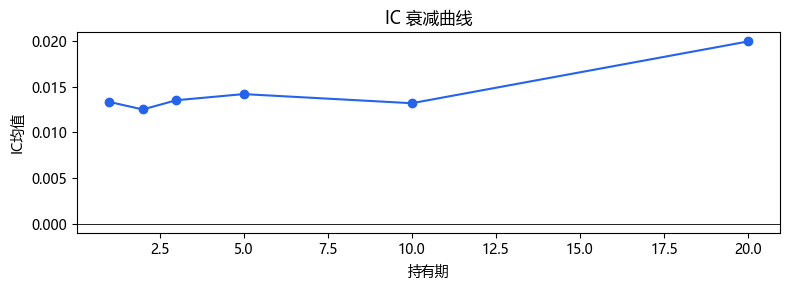

In [5]:
rows = []
for k in [1, 2, 3, 5, 10, 20]:
    ic = ic_series(rev_p, fwd_returns(k))
    rows.append({'持有期': k, 'IC均值': ic.mean(), 'IR': ic.mean()/ic.std(),
                 '胜率': (ic > 0).mean()})
decay = pd.DataFrame(rows).set_index('持有期')
print(decay.round(4))
decay['IC均值'].plot(figsize=(8, 3), marker='o', color='#2563eb')
plt.axhline(0, color='black', lw=.6); plt.title('IC 衰减曲线'); plt.ylabel('IC均值')
plt.tight_layout(); plt.show()

## 七、用同一套方法快速对比几个因子

IC 方法的真正威力是**横向筛选因子**。下面快速算几个常见因子，看谁更有效（03.6 会系统实现因子库）。

In [6]:
# 构造几个候选因子（都做 Rank 预处理）
factors = {
    'REV5  (5日反转)': process_factor(-close.pct_change(5)),
    'REV20 (20日反转)': process_factor(-close.pct_change(20)),
    'MOM60 (60日动量)': process_factor(close.pct_change(60)),
    'VOL20 (20日波动率,低波)': process_factor(-close.pct_change().rolling(20).std()),
}
table = {}
for name, f in factors.items():
    table[name] = ic_summary(ic_series(f, fwd1)).round(4)
print(pd.DataFrame(table).T)

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


                     IC均值   IC标准差      IR    IC胜率
REV5  (5日反转)       0.0233  0.2033  0.1148  0.5444
REV20 (20日反转)      0.0133  0.2220  0.0601  0.5150
MOM60 (60日动量)     -0.0062  0.2290 -0.0271  0.4771
VOL20 (20日波动率,低波)  0.0223  0.2640  0.0845  0.5327


**结论：** 在沪深300大盘股上，这几个简单量价因子的日频 IC 都偏弱（这是大盘股池的客观结果）。
- 这提示我们：① 单一简单量价因子在大盘股上 alpha 有限；② 真正的 alpha 往往来自**多因子合成、更精细的另类数据、或在更小市值/更大股票池**中挖掘；
- 后续 03.6 会在更大因子库上筛选，模块 4 会用机器学习把弱因子合成出更强的预测。

## 八、小结与面试要点

- **IC = 因子值与未来收益的截面相关系数**；RankIC（Spearman）稳健，A 股常用。
- 四大指标：**IC 均值（强弱）、IC 标准差（稳定性）、IR=均值/标准差（最重要）、IC 胜率**。
- 经验门槛：IC>0.03、IR>0.5、胜率>50%。
- **IC 衰减**看预测力的持有期；**IC 时间序列**看稳定性和极端行情影响。
- 因子研究常态：大部分因子经 IC 检验后被淘汰。

**面试高频：**
- IC 和 RankIC 的区别？为什么用 RankIC？（答：Spearman 用排名，抗极值、抗厚尾）
- IR 怎么算？为什么比单看 IC 均值重要？（答：IR 同时考虑收益和稳定性，IR 高才可持续）
- 一个因子 IC 均值为正但 IR 很低，说明什么？（答：方向偶尔对但极不稳定，不可用）
- IC 衰减能告诉你什么？（答：因子预测力的有效期，决定调仓频率）

## 动手练习
1. 把未来收益改成 5 日，重新算 IR，对比是否更稳定；
2. 计算换手率因子（若有）的 IC，与反转因子对比；
3. 思考：为什么 IC 评估要"逐截面、滚动"，不能全样本算一个相关系数？

---
下一节 **03.4 分层回测：把因子分组，看收益是否单调、多空能否赚钱**。